# 03b - Backtest com a ENA do ECMWF (sem oráculo)

Mesma regra de vazamento do `02g` (k = 15, peso igual na trajetória; ANDE/PCH/carga do deck; σ só com o passado), agora
com a **ENA de referência prevista**. Pareamento D031: o deck do mês M usa a rodada do ECMWF de M; o próprio mês M usa a ENA
do PMO e M+1 em diante, o ECMWF. Decks com rodada do ECMWF: jan/2025 a set/2026 (16). Horizonte M+1 a M+6.

| Variante | Referência de ENA (M+1 em diante) | Probabilidade de cada cor |
|---|---|---|
| Oráculo | ENA real do PMO (teto) | σ do erro histórico |
| A: ECMWF média | média `precip` | σ do erro histórico das previsões A |
| B: ECMWF membros | cada um dos 51 membros recentrados escolhe 15 séries | fração dos membros em cada cor |
| Climatologia | 100% da MLT (piso) | σ do erro histórico |

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from forecast_bandeiras import backtest, ecmwf, graficos, load, newave

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
base = pd.read_parquet(load.DATA_PROCESSED / "base_mensal.parquet")
base.index = base.index.to_period("M")
base["cor_oficial"] = [c if isinstance(c, str) else r for c, r in zip(base.cor_boletim, base.cor_regra)]
base["x_real"] = base.pld_gatilho_boletim * (1 - base.gsf_band_boletim).clip(lower=0)
ORD = ["Verde", "Amarela", "Vermelha 1", "Vermelha 2"]
rodadas = set(ecmwf.rodadas_disponiveis())
decks = [(a, m) for a, m in backtest.decks_disponiveis() if pd.Period(f"{a}-{m:02d}", "M") in rodadas]
len(decks)

16

In [2]:
saidas = {"oráculo": [], "A: ECMWF média": [], "B: ECMWF membros": [], "climatologia": []}
for d in decks:
    pr = backtest.preparar_deck(*d, base)
    dk = pr["inicio"]
    saidas["oráculo"].append(backtest.prever_com_parametros(pr, base))
    saidas["A: ECMWF média"].append(backtest.prever_com_referencia(pr, ecmwf.referencia_media(dk, base)))
    saidas["B: ECMWF membros"].append(backtest.prever_com_membros(pr, ecmwf.referencia_membros(dk, base)))
    saidas["climatologia"].append(backtest.prever_com_referencia(pr, ecmwf.referencia_climatologia(dk, base)))
res = {}
for nome, lst in saidas.items():
    p = pd.concat(lst, ignore_index=True).merge(
        base[["cor_oficial", "x_real", "gsf_band_boletim", "pld_gatilho_boletim"]], left_on="alvo", right_index=True)
    p["erro_x"] = p.x_real - p.x_medio
    if nome != "B: ECMWF membros":
        sig = {dk: backtest.sigma_disponivel(p, dk)[0] for dk in p.deck.unique()}
        p["sigma"] = p.deck.map(sig)
        probs = [newave.probabilidade_calibrada(x, s, g) if pd.notna(s) else pd.Series(np.nan, index=ORD)
                 for x, s, g in zip(p.x_medio, p.sigma, p.gsf_medio)]
        for c in ORD:
            p[f"p_{c}"] = [q[c] for q in probs]
    p["p_cor_real"] = [p.loc[i, f"p_{c}"] for i, c in zip(p.index, p.cor_oficial)]
    p["p_cor_prevista"] = [p.loc[i, f"p_{c}"] for i, c in zip(p.index, p.cor_media)]
    obs = np.array([[float(c == o) for c in ORD] for o in p.cor_oficial])
    p["brier"] = ((p[[f"p_{c}" for c in ORD]].to_numpy() - obs) ** 2).sum(axis=1)
    res[nome] = p[(p.h >= 1) & (p.h <= 6)].copy()
pd.to_pickle(res, load.DATA_PROCESSED / "backtest_ecmwf.pkl")

## Resultado (mesmas 89 previsões em todas as variantes)

In [3]:
linhas = []
for nome, q in res.items():
    cp = q[q.p_cor_real.notna()]
    linhas.append({"variante": nome, "previsões": len(q), "acerto da cor": (q.cor_media == q.cor_oficial).mean(),
                   "erro GSF": (q.gsf_medio - q.gsf_band_boletim).abs().mean(),
                   "erro PLD": (q.pld_medio - q.pld_gatilho_boletim).abs().mean(), "erro X": (q.x_medio - q.x_real).abs().mean(),
                   "n com prob.": len(cp), "prob. cor real": cp.p_cor_real.mean(), "Brier": cp.brier.mean()})
pd.DataFrame(linhas).set_index("variante")

,previsões,acerto da cor,erro GSF,erro PLD,erro X,n com prob.,prob. cor real,Brier
variante,,,,,,,,
oráculo,90,0.722,0.040,67.383,12.437,54,0.710,0.321
A: ECMWF média,89,0.573,0.045,88.392,19.555,53,0.553,0.552
B: ECMWF membros,89,0.539,0.044,87.921,20.673,89,0.540,0.560
climatologia,89,0.382,0.063,153.014,33.293,53,0.527,0.619


In [4]:
pd.DataFrame({n: q.groupby("h").apply(lambda g: (g.cor_media == g.cor_oficial).mean(), include_groups=False)
              for n, q in res.items()}).mul(100).round(0)  # acerto da cor (%) por horizonte

,oráculo,A: ECMWF média,B: ECMWF membros,climatologia
h,,,,
1,69.000,75.000,69.000,62.000
2,67.000,67.000,73.000,47.000
3,73.000,73.000,60.000,40.000
4,67.000,40.000,40.000,27.000
5,80.000,53.000,47.000,27.000
6,79.000,31.000,31.000,23.000


## Matrizes (cor prevista e distribuição)

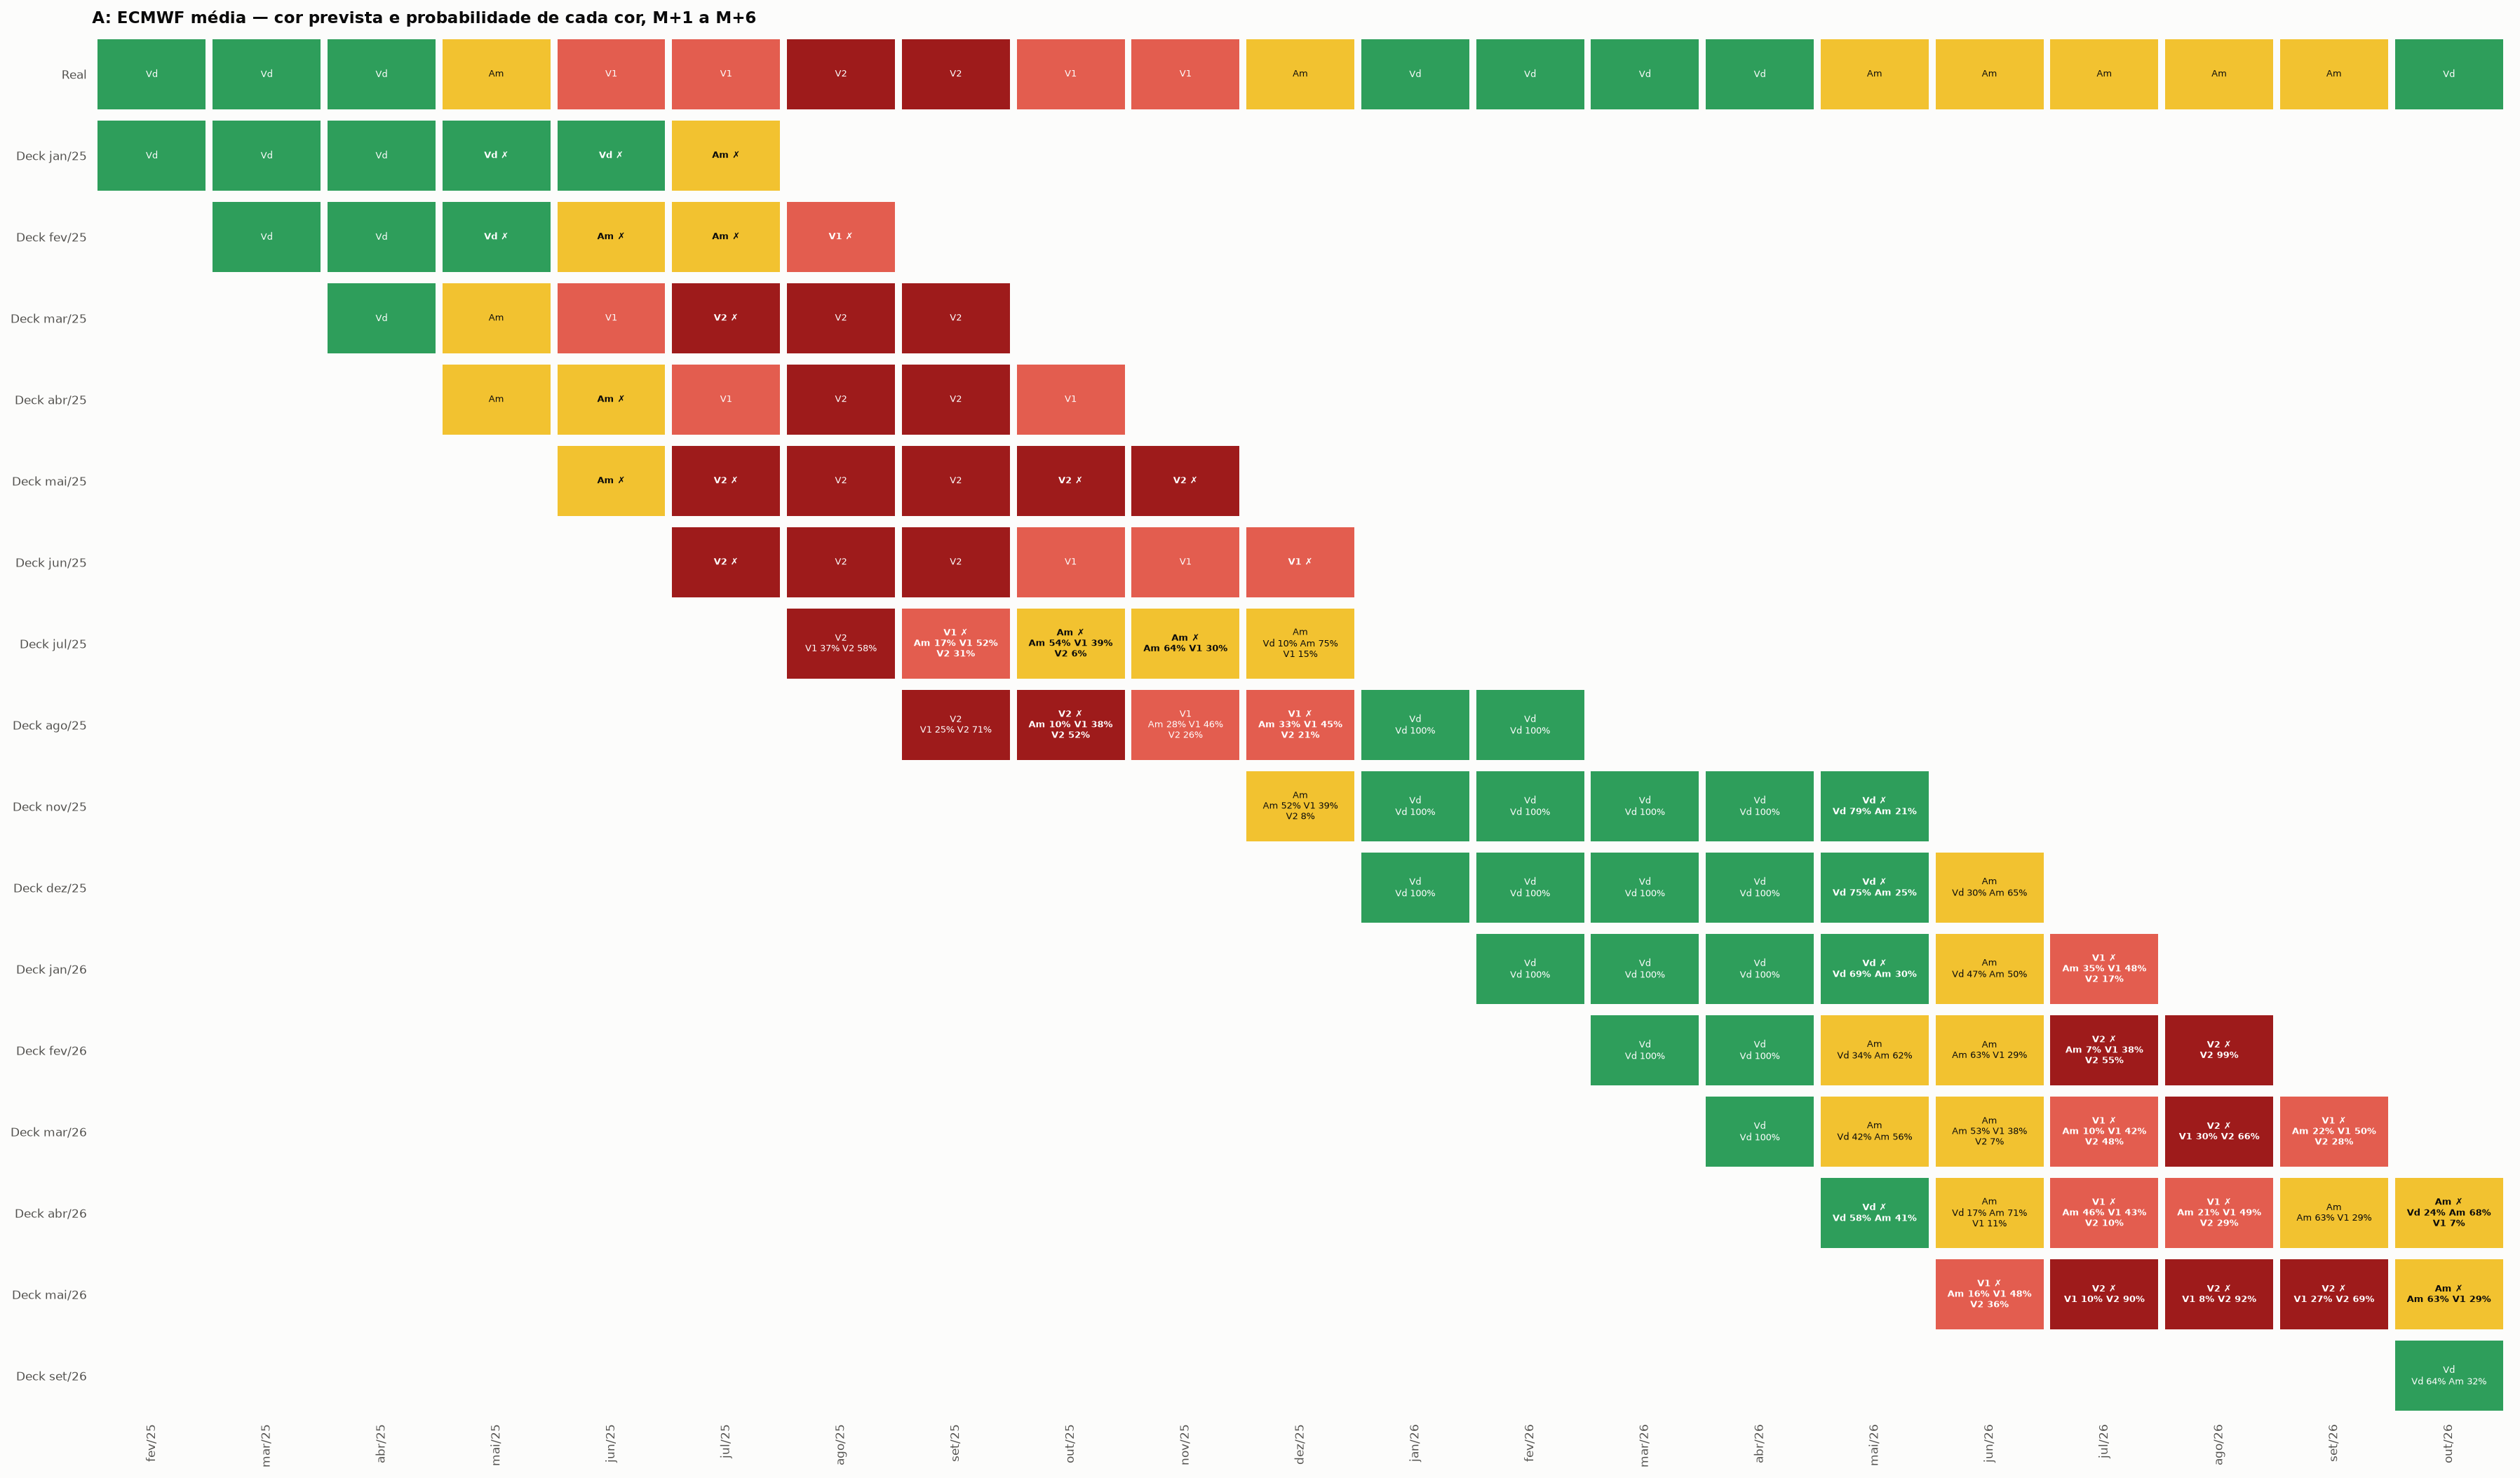

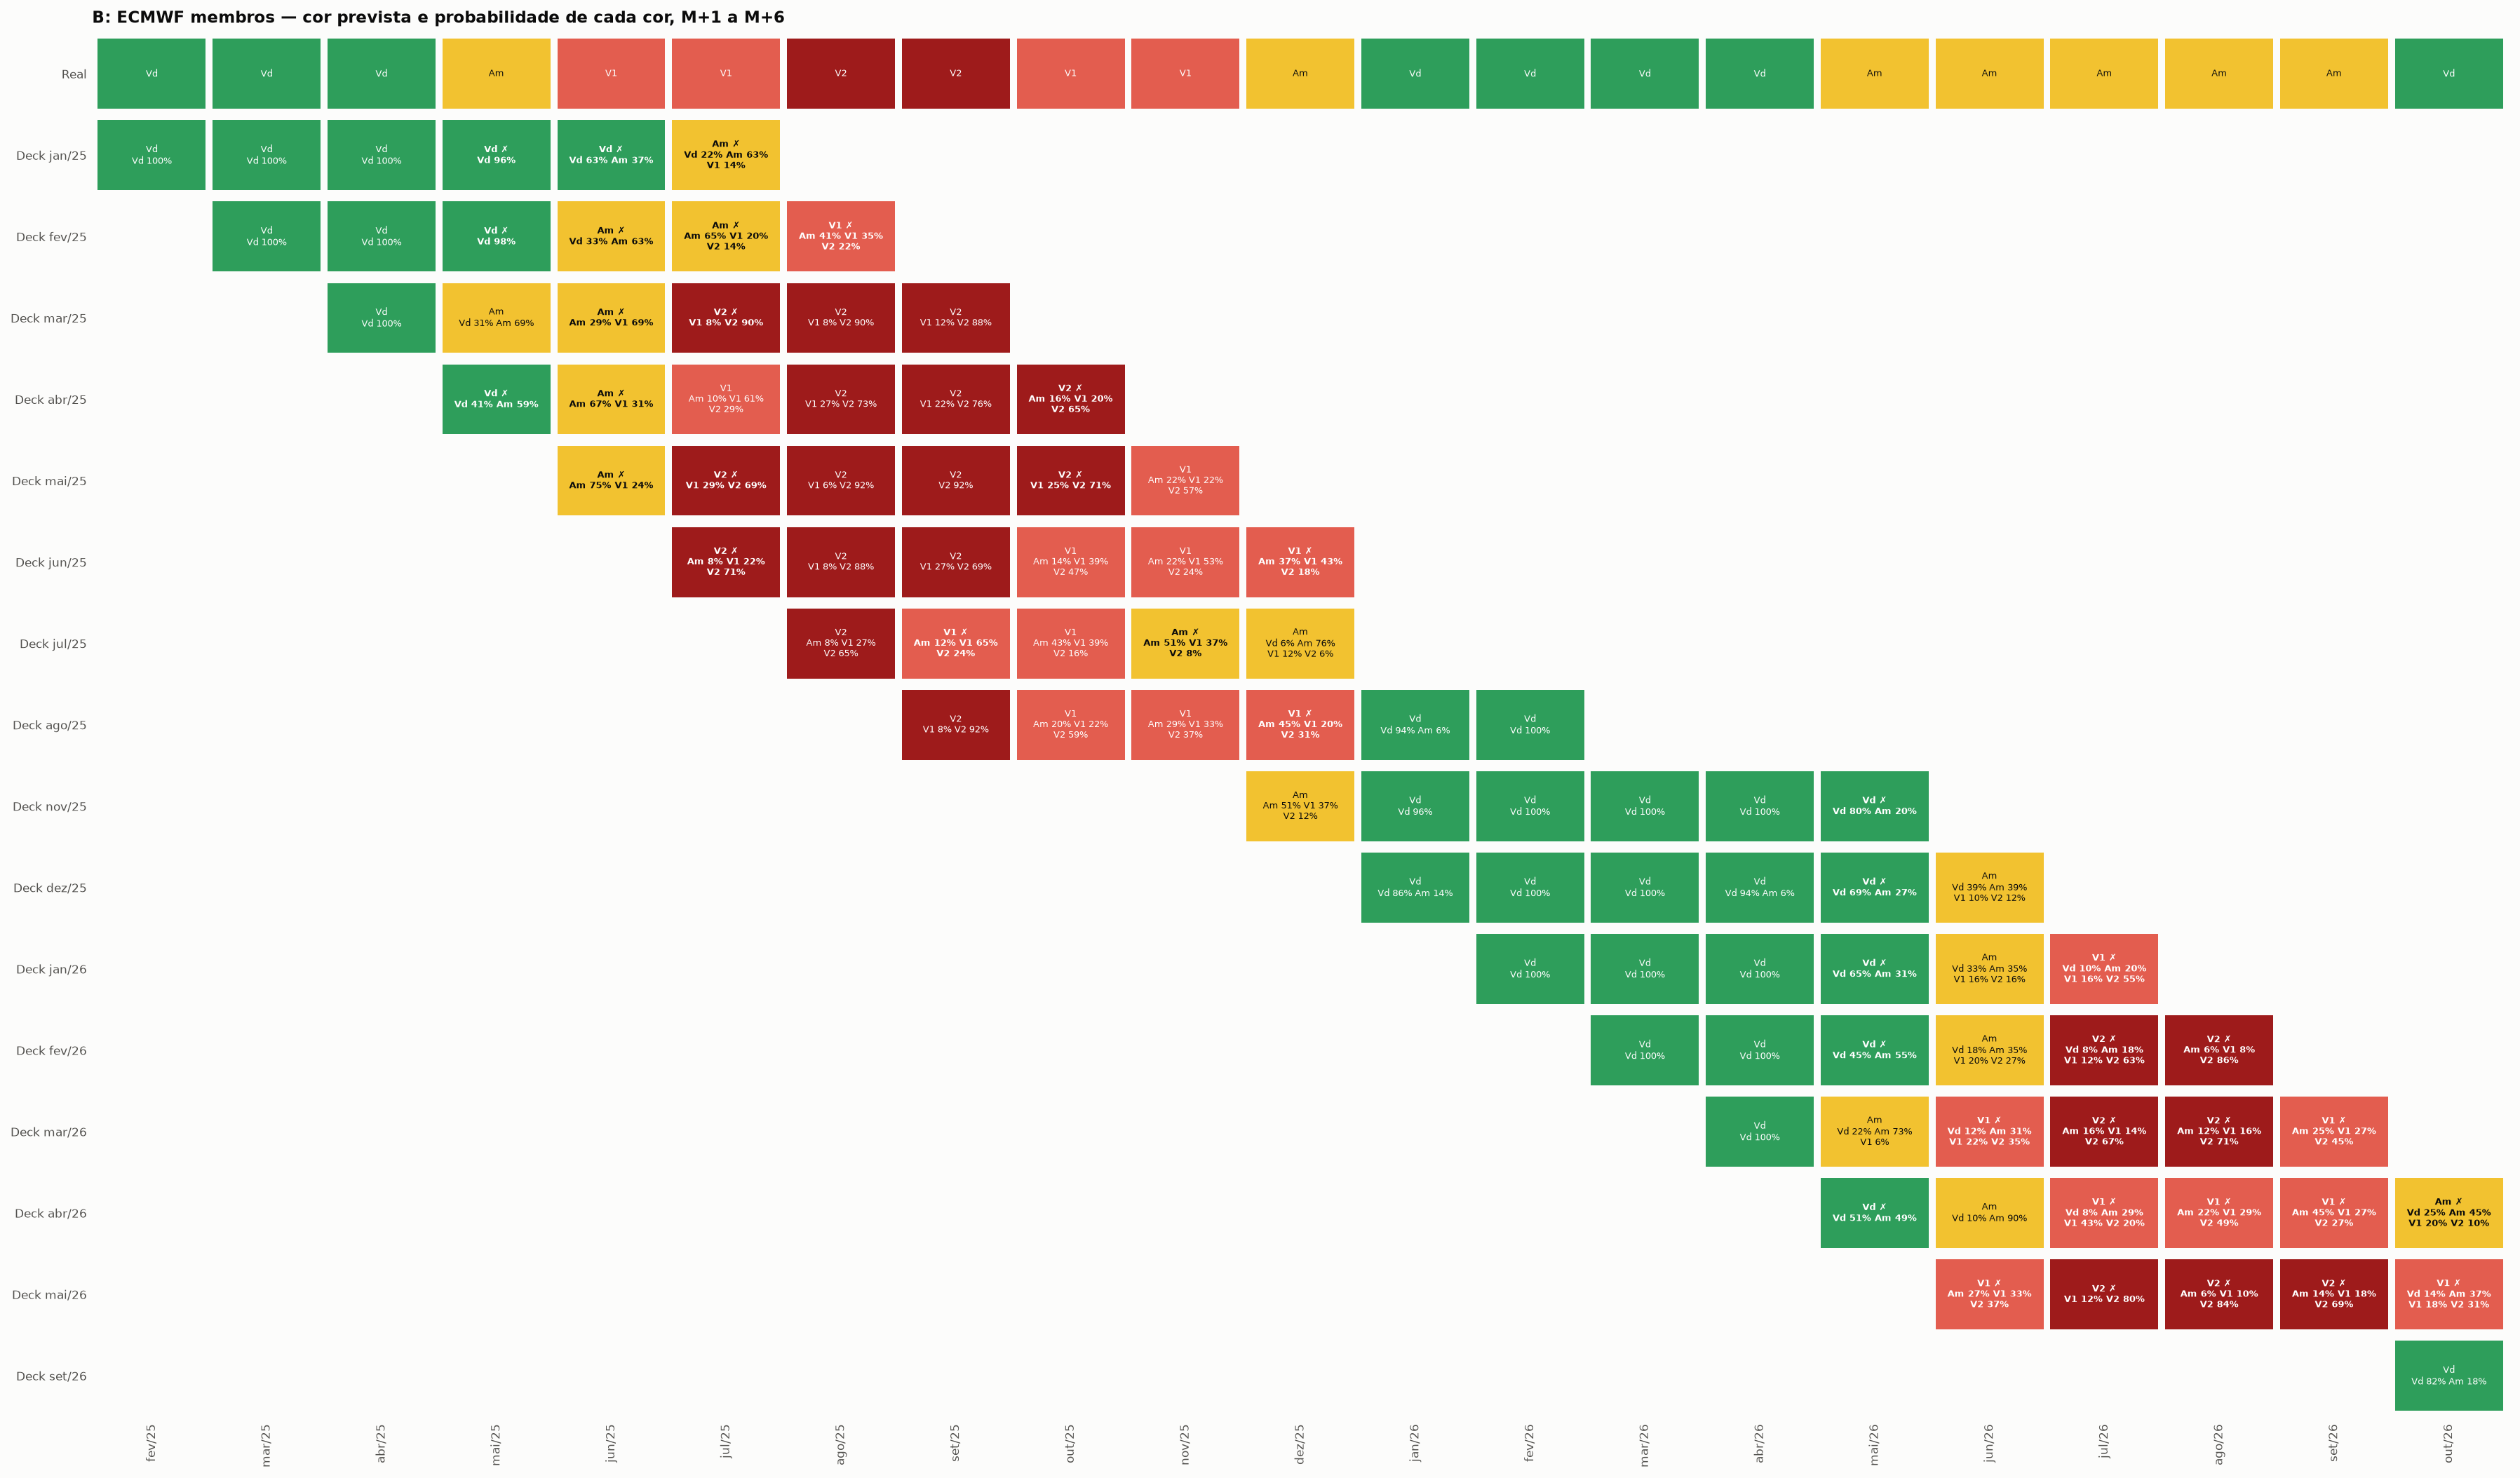

In [5]:
for nome, arq in (("A: ECMWF média", "12a_matriz_ecmwf_media.png"), ("B: ECMWF membros", "12b_matriz_ecmwf_membros.png")):
    display(Image(graficos.matriz_backtest(res[nome], f"{nome} — cor prevista e probabilidade de cada cor, M+1 a M+6",
                                           f"ecmwf/{arq}", distribuicao=True)))

## Onde o ECMWF erra (M+4 a M+6)

In [6]:
a, o = res["A: ECMWF média"], res["oráculo"]
j = a.merge(o[["deck", "alvo", "cor_media", "pld_medio"]], on=["deck", "alvo"], suffixes=("_A", "_oraculo"))
er = j[(j.h >= 4) & (j.cor_media_A != j.cor_oficial)]
print(f"M+4 a M+6: acerto A {(j[j.h >= 4].cor_media_A == j[j.h >= 4].cor_oficial).mean():.0%} | oráculo {(j[j.h >= 4].cor_media_oraculo == j[j.h >= 4].cor_oficial).mean():.0%}")
print(f"nos erros: GSF A − real {(er.gsf_medio - er.gsf_band_boletim).mean():+.3f} | PLD A − real {(er.pld_medio_A - er.pld_gatilho_boletim).mean():+.0f} R$/MWh")
er[["deck", "alvo", "h", "cor_oficial", "cor_media_A", "cor_media_oraculo", "gsf_band_boletim", "gsf_medio", "pld_gatilho_boletim", "pld_medio_A", "pld_medio_oraculo"]]

M+4 a M+6: acerto A 42% | oráculo 74%
nos erros: GSF A − real -0.002 | PLD A − real +25 R$/MWh


,deck,alvo,h,cor_oficial,cor_media_A,cor_media_oraculo,gsf_band_boletim,gsf_medio,pld_gatilho_boletim,pld_medio_A,pld_medio_oraculo
3,2025-01,2025-05,4,Amarela,Verde,Verde,0.830,0.900,241.890,69.846,115.737
4,2025-01,2025-06,5,Vermelha 1,Verde,Amarela,0.750,0.790,310.350,85.458,153.020
5,2025-01,2025-07,6,Vermelha 1,Amarela,Amarela,0.650,0.690,228.450,158.314,144.031
9,2025-02,2025-06,4,Vermelha 1,Amarela,Amarela,0.750,0.790,310.350,158.166,215.958
10,2025-02,2025-07,5,Vermelha 1,Amarela,Vermelha 1,0.650,0.700,228.450,216.937,232.892
11,2025-02,2025-08,6,Vermelha 2,Vermelha 1,Vermelha 1,0.630,0.690,310.300,243.588,276.278
15,2025-03,2025-07,4,Vermelha 1,Vermelha 2,Vermelha 1,0.650,0.670,228.450,327.604,281.559
28,2025-05,2025-10,5,Vermelha 1,Vermelha 2,Vermelha 1,0.690,0.710,297.320,356.594,324.507
29,2025-05,2025-11,6,Vermelha 1,Vermelha 2,Vermelha 1,0.720,0.750,333.390,405.678,352.556
35,2025-06,2025-12,6,Amarela,Vermelha 1,Amarela,0.840,0.830,304.020,430.915,372.780
